# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
# TODO 1
NX_, NY_, NZ_ = 512, 512, 300
DX, DY, DZ = 0.5, 0.5, 1.0                     
n_voxels = NX_ * NY_ * NZ_
scan_mb = n_voxels * 2 / 1024**2                

# TODO 2
extent_mm = (NX_ * DX, NY_ * DY, NZ_ * DZ)      # (x, y, z) in mm
voxel_mm3 = DX * DY * DZ

# TODO 3
rays_per_frame = NX_ * NZ_                      
samples_per_frame = rays_per_frame * NY_       
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35        

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_

1. **The anatomy would look distorted.** Coronal and sagittal views have z on one screen axis. A z-step is 1.0 mm but an in-plane step is only 0.5 mm. If every voxel is drawn as a square pixel, the head gets squashed to half its real height. A round tumour would then look like a flat ellipse, and the radiologist might misjudge its shape or how it relates to nearby structures.
2. **Measurements would be wrong.** Distances, angles and volumes counted in voxels instead of millimetres are off along z by a factor of 2. A tumour 20 mm tall would measure as 10 mm. The voxel volume in mm³ has to come from the real spacing (0.25 mm³ here), not from assuming 1 × 1 × 1.

There's also a smaller effect: resolution along z is coarser, so even with the correct aspect ratio those views are slightly blurrier vertically than the axial view.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

1 candidate components; largest = 431 voxels; centroid (z, y, x) = (28, 40, 41)


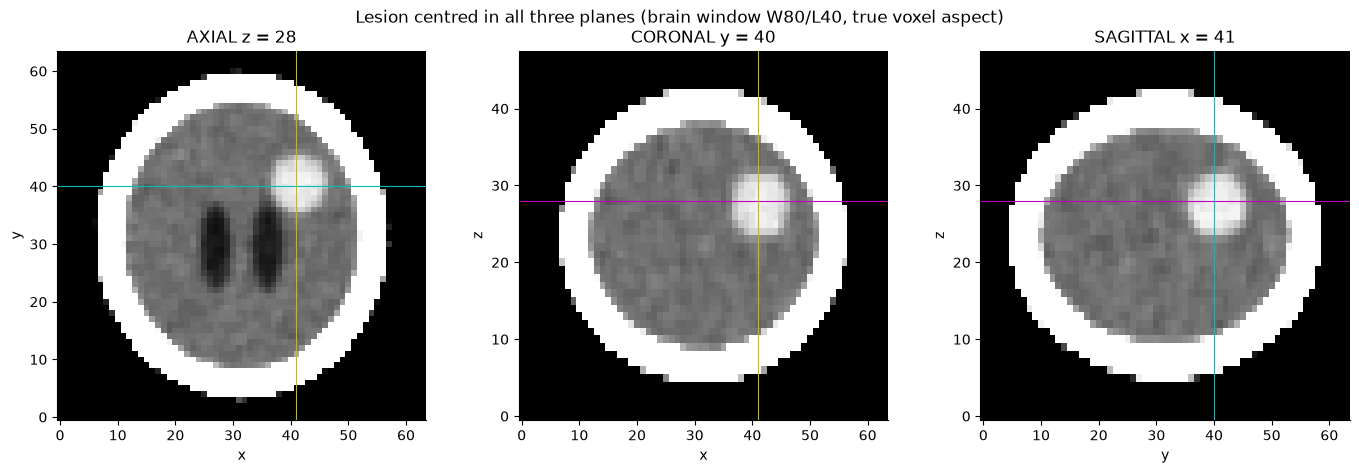

True tumour centroid (z, y, x) = [27.5 40.5 41.5]; my centroid is 2.9 mm away


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1
bone_mask = vol > 300
inside = ndimage.binary_fill_holes(bone_mask) & ~bone_mask          # everything enclosed by the skull
inside = ndimage.binary_erosion(inside, iterations=3)               # peel off the partial-volume shell under the bone
candidates = (vol > 55) & (vol < 90) & inside

# TODO 2
comp, n_comp = ndimage.label(candidates)
sizes = ndimage.sum(candidates, comp, index=np.arange(1, n_comp + 1))
lesion = comp == (np.argmax(sizes) + 1)                             # largest connected component
cz, cy, cx = np.round(np.argwhere(lesion).mean(axis=0)).astype(int)
print(f"{n_comp} candidate components; largest = {lesion.sum()} voxels; centroid (z, y, x) = ({cz}, {cy}, {cx})")

# TODO 3
W, L = 80, 40
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
axes[0].imshow(window(vol[cz], W, L), cmap="gray", origin="lower")
axes[0].axhline(cy, color="c", lw=0.8); axes[0].axvline(cx, color="y", lw=0.8)
axes[0].set_title(f"AXIAL z = {cz}"); axes[0].set_xlabel("x"); axes[0].set_ylabel("y")
axes[1].imshow(window(vol[:, cy, :], W, L), cmap="gray", origin="lower", aspect=ASPECT)
axes[1].axhline(cz, color="m", lw=0.8); axes[1].axvline(cx, color="y", lw=0.8)
axes[1].set_title(f"CORONAL y = {cy}"); axes[1].set_xlabel("x"); axes[1].set_ylabel("z")
axes[2].imshow(window(vol[:, :, cx], W, L), cmap="gray", origin="lower", aspect=ASPECT)
axes[2].axhline(cz, color="m", lw=0.8); axes[2].axvline(cy, color="c", lw=0.8)
axes[2].set_title(f"SAGITTAL x = {cx}"); axes[2].set_xlabel("y"); axes[2].set_ylabel("z")
plt.suptitle("Lesion centred in all three planes (brain window W80/L40, true voxel aspect)")
plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
true_c = np.argwhere(labels == 5).mean(axis=0)
err_mm = np.linalg.norm((np.array([cz, cy, cx]) - true_c) * np.array(SPACING))
print(f"True tumour centroid (z, y, x) = {np.round(true_c, 1)}; my centroid is {err_mm:.1f} mm away")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_

A voxel on the boundary between bone (~800 HU) and brain (~35 HU) is partly filled with each, so the scanner records an average of the two (the **partial-volume effect**). Across that boundary the values pass through every intensity in between, including the tumour's 55–90 HU window. This gives a thin shell just inside the skull whose HU values match the tumour exactly. That's the overlapping-range problem from Slide 28: intensity alone can't tell "tumour" apart from "brain blurred with bone".

The shell is a closed ring all the way around the brain, so without erosion it would form a large connected component. "Keep the largest component" could easily pick the shell instead of the lesion, and its centroid would land near the middle of the head. Eroding the inside-skull mask by 3 voxels (≈ 9–12 mm) removes that shell, so only deep candidates are left. In the run, exactly one component survived and its centroid was 2.9 mm from the true centre, which is less than one voxel. The trade-off is that a tumour touching the inner skull would also get eroded away, so this rule only works for lesions that sit deeper in the brain.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold_hu,voxels,volume_ml,dice_vs_truth
0,45,535,19.26,0.929
1,50,464,16.70,0.994
2,55,431,15.52,0.963
3,60,350,12.60,0.860
4,65,273,9.83,0.741
5,70,170,6.12,0.536


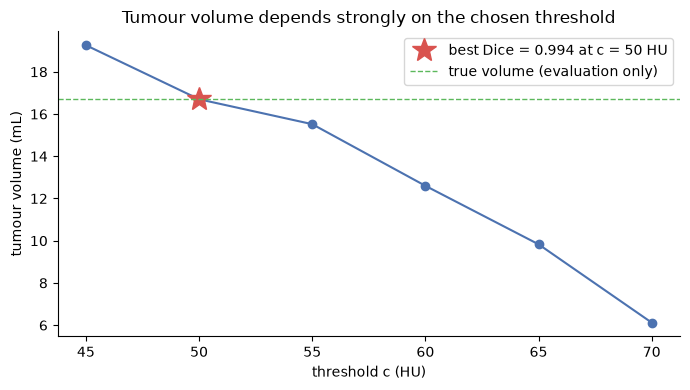

Across c = 45..70 HU the volume ranges 6.1 - 19.3 mL.
Reported to the surgeon (plausible band c = 50..60 HU): 12.6 - 16.7 mL, best estimate ~16.7 mL (c = 50 HU).


In [4]:
truth = labels == 5
rows = []
# TODO 1 & 2
thresholds = [45, 50, 55, 60, 65, 70]
for c in thresholds:
    comp_c, _ = ndimage.label(vol > c)
    region = comp_c == comp_c[cz, cy, cx]                           # component containing the lesion centre
    d = 2 * (region & truth).sum() / (region.sum() + truth.sum())   # evaluation only
    rows.append({"threshold_hu": c, "voxels": int(region.sum()),
                 "volume_ml": round(region.sum() * VOXEL_MM3 / 1000, 2), "dice_vs_truth": round(d, 3)})

table = pd.DataFrame(rows)
display(table)

# TODO 3
best = table.loc[table.dice_vs_truth.idxmax()]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table.threshold_hu, table.volume_ml, "o-", color="#4C72B0")
ax.plot(best.threshold_hu, best.volume_ml, "*", ms=18, color="#D9534F", label=f"best Dice = {best.dice_vs_truth:.3f} at c = {best.threshold_hu:.0f} HU")
ax.axhline(truth.sum() * VOXEL_MM3 / 1000, color="#5cb85c", ls="--", lw=1, label="true volume (evaluation only)")
ax.set_xlabel("threshold c (HU)"); ax.set_ylabel("tumour volume (mL)")
ax.set_title("Tumour volume depends strongly on the chosen threshold")
ax.legend(); plt.tight_layout(); plt.show()

# TODO 4
plausible = table[(table.threshold_hu >= 50) & (table.threshold_hu <= 60)]
print(f"Across c = 45..70 HU the volume ranges {table.volume_ml.min():.1f} - {table.volume_ml.max():.1f} mL.")
print(f"Reported to the surgeon (plausible band c = 50..60 HU): {plausible.volume_ml.min():.1f} - {plausible.volume_ml.max():.1f} mL, "
      f"best estimate ~{best.volume_ml:.1f} mL (c = {best.threshold_hu:.0f} HU).")

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_

**Choosing c:** I'd base it on the two tissues the edge separates. The tumour enhances to ~70 HU and the surrounding brain is ~35 HU, so the boundary sits roughly halfway, at about 50–55 HU (the half-maximum rule for a blurred edge). I'd check this two ways. First, the histogram should show the two populations with the threshold in the valley between them. Second, the contour at that c should be overlaid on the axial/coronal/sagittal slices so the radiologist can confirm it follows the visible edge. I'd also prefer a c where the volume-vs-threshold curve is fairly flat (here 50–55 HU), because a small change in c there barely moves the answer. Whatever c is chosen should be written down and reused on follow-up scans, so changes in volume reflect the tumour and not the method.

**Showing the uncertainty:** I wouldn't report a single number. I'd say "≈ 13–17 mL (c = 50–60 HU), most likely ≈ 16 mL" and show the volume-vs-threshold plot with that band shaded. On the slices I'd draw nested contours, for example inner (c = 60) and outer (c = 50), so the surgeon can see where the edge is uncertain. In 3-D, the outer surface would be translucent and the inner surface opaque. The gap between them shows the uncertainty directly, so it isn't hidden behind a single crisp surface.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

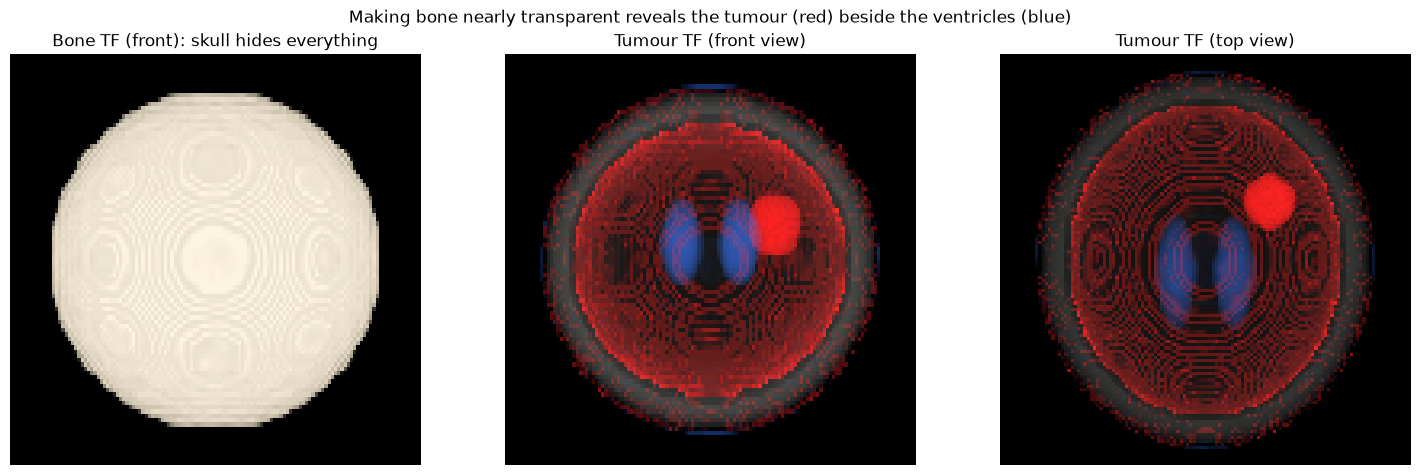

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
RED, BLUE, WHITE, BLACK = (1, 0.1, 0.1), (0.2, 0.45, 1), (1, 1, 0.95), (0, 0, 0)
tumour_tf = make_tf([
    (-1000, BLACK, 0),     (0, BLACK, 0),            # air, fat, scalp: invisible
    (5, BLUE, 0.03),       (20, BLUE, 0.03),         # CSF / ventricles: faint blue
    (27, BLACK, 0),        (58, BLACK, 0),           # brain: invisible
    (65, RED, 0.18),       (82, RED, 0.18),          # tumour: red, thick -> builds up to near-opaque
    (92, BLACK, 0),        (250, BLACK, 0),          # gap between tumour and bone
    (400, WHITE, 0.005),   (1500, WHITE, 0.008),     # bone: almost transparent, context only
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render | your TF front view | your TF top view
Cb, _ = render(vol, bone_tf, axis=1)
Cf, _ = render(vol, tumour_tf, axis=1)
Ct, _ = render(vol, tumour_tf, axis=0)
axes[0].imshow(np.clip(Cb, 0, 1), origin="lower", aspect=ASPECT); axes[0].set_title("Bone TF (front): skull hides everything")
axes[1].imshow(np.clip(Cf / Cf.max(), 0, 1), origin="lower", aspect=ASPECT); axes[1].set_title("Tumour TF (front view)")
axes[2].imshow(np.clip(Ct / Ct.max(), 0, 1), origin="lower"); axes[2].set_title("Tumour TF (top view)")
for ax in axes: ax.axis("off")

# TODO 4: suptitle
plt.suptitle("Making bone nearly transparent reveals the tumour (red) beside the ventricles (blue)")
plt.tight_layout(); plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_

The rim comes from the **transfer-function selection / overlapping scalar ranges** challenge, caused by the partial-volume effect. Voxels at the bone–brain boundary average out to 60–85 HU, the same values as the tumour. Near the edge of the image, rays also travel tangentially through that shell, so many of these samples pile up and the rim gets brighter.

A 1-D transfer function T(s) → (C, α) only sees the scalar value at each sample. If two voxels have the same HU, they get the same colour and opacity, regardless of where they are or what they're connected to. Any TF that makes the tumour red will therefore make the shell red too, and narrowing the red band only trades rim brightness for a fainter tumour.

**Segmentation** (Slides 31–32) fixes this. Use the Task 2 region (inside the skull, eroded, largest connected component) as a tumour label, then render by label: red only where label = tumour, and everything else follows the faint bone/CSF TF. Segmentation uses spatial information (position, connectivity, distance from the skull) that a value-only TF has no access to.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_

The CT shows a single contrast-enhancing lesion, about 3 cm across, in the upper half of the brain. It sits to the right of and slightly behind the lateral ventricles, clear of the skull (centre at voxel z = 28, y = 40, x = 41). Its volume is **about 13–17 mL**, most likely around 16 mL. The exact figure depends on where the tumour edge is drawn (50–60 HU), so please treat it as a range rather than a precise number. I'd open the meeting with the **segmentation overlay on the three MPR slices**. Slices show the inside of the head without occlusion and keep the true intensities visible, and the overlaid outline is the same region the volume was measured from, so the board can check both the location and the number together. The 3-D render is useful for showing the tumour next to the ventricles, but keep two things in mind. It is a projection, so depth is ambiguous: structures that look adjacent may be at different depths. And the faint red rim under the skull is a partial-volume artefact of the transfer function, not tumour spread.